# Extension — A second pair: INTC/AMD

Optional extension "Second pair". I repeat the Phase 2 procedure, unchanged, on Intel (INTC) and AMD, to
see if the KO/PEP result comes back on a different pair.

**Result**
- In-sample the grid is weaker than for KO/PEP. The 25 Sharpe ratios go from −0.18 to 0.19, and only one
  zone score is positive. The rule picks threshold 2.5 and window 60 days: Sharpe 0.19, t-stat 0.82, with a
  worst drawdown of −53%.
- The single out-of-sample run makes money: Sharpe 0.42, t-stat 1.17, 9.1% a year. My prediction (a loss,
  because AMD went up and Intel went down) was wrong.
- I do not read this as a working strategy. The t-stat is below 2 in both periods, and the 500-day rolling
  β moves between −1.36 and 0.90, so there is no stable relation to trade either.
- So on both pairs the in-sample result is small and not significant, and the out-of-sample result goes
  one way on KO/PEP (−0.53) and the other way on INTC/AMD (0.42). This looks like noise more than a
  repeatable effect.

I did this after seeing the KO/PEP results, with less time than the main pair. Terms are in the README
glossary.

## 1. Set-up and data

Daily adjusted close of INTC and AMD from Yahoo Finance, downloaded once and saved as a checkpoint
(`data/prices_second_pair_raw.pkl`), like the KO/PEP prices.

In [1]:
import logging

import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio

from pairs.backtest import run_zscore_strategy, select_stable_cell, summarize
from pairs.config import PAIR, PHASE2_STRATEGY, SECOND_PAIR, SIGNAL_GRID, Settings
from pairs.data import _download, load_pair_prices
from pairs.explore import longest_gaps, select_until
from pairs.logging_setup import configure_logging
from pairs.plots import equity_figure, finish_figure, save_figure
from pairs.spread import fit_hedge_ratio
from pairs.stability import rolling_hedge_ratio
from pairs.trials import count_trials, log_trial

configure_logging(logging.WARNING)  # notebook output: tables and charts only, no progress logs
pio.renderers.default = "plotly_mimetype+png"
settings = Settings.from_env()
figures_dir = settings.results_dir / "figures"
trials_db = settings.results_dir / "trials.sqlite"
P2 = SECOND_PAIR
A, B, PAIR_NAME = P2.ticker_a, P2.ticker_b, f"{P2.ticker_a}/{P2.ticker_b}"
SOURCE_ALL = (
    "Source: Yahoo Finance adjusted close, 3 Jan 2000 - 9 Oct 2026."
    " Shaded: out-of-sample (run once)."
)

path = settings.data_dir / "prices_second_pair_raw.pkl"
raw = pd.read_pickle(path) if path.exists() else _download([A, B], P2.start, P2.end, path)
all_prices = pd.DataFrame(raw["Adj Close"][[A, B]]).dropna()
all_prices.index = pd.DatetimeIndex(all_prices.index).tz_localize(None)
all_prices = all_prices.loc[pd.Timestamp(P2.start) : pd.Timestamp(P2.end)]
assert (all_prices > 0).all().all() and all_prices.index.is_unique
prices = select_until(all_prices, P2.in_sample_end)  # in-sample only: every estimate uses this
start = prices.index[max(SIGNAL_GRID.windows) - 1]  # first day with a full 250-day window
oos_start = all_prices.index[all_prices.index > pd.Timestamp(P2.in_sample_end)][0]
pd.Series(
    {
        "days": len(all_prices),
        "in-sample days": len(prices),
        "backtests start": start.date(),
        "out-of-sample": f"{oos_start.date()} - {all_prices.index[-1].date()}",
    }
)

days                                  6733
in-sample days                        4779
backtests start                 2000-12-27
out-of-sample      2019-01-02 - 2026-10-09
dtype: object

In [2]:
rets = all_prices.pct_change()
big_moves = rets[(rets.abs() > 0.25).any(axis=1)].round(3)
gaps = longest_gaps(all_prices.index, 3)
display(gaps)
big_moves  # days where either stock moved more than 25%

,from,to,calendar_days
0,2001-09-10,2001-09-17,7
1,2006-12-29,2007-01-03,5
2,2012-10-26,2012-10-31,5


Ticker,INTC,AMD
Date,,
2001-07-06,-0.047,-0.274
2002-10-03,-0.032,-0.324
2002-10-21,0.068,0.261
2005-01-11,-0.015,-0.262
2016-04-22,-0.010,0.523
2024-08-02,-0.261,-0.000


The data cover 6,733 days where both stocks trade. The longest gap is the market closure after
11 September 2001 (7 calendar days). Six days have a move above 25%, all in a single stock and none
followed by a jump back, so they look like real news (for example AMD +52% on 22 April 2016 and Intel
−26% on 2 August 2024) and not like a missing split adjustment. I did not check them one by one against
the news.

## 2. The rules and my prediction

The pair and its dates were fixed in `src/pairs/config.py` (`SECOND_PAIR`) and committed before I
downloaded any INTC or AMD price. INTC/AMD was already the second pair I had picked in the morning, when I
compared candidate pairs. Everything else is the Phase 2 procedure as it is:

- same split: in-sample 3 Jan 2000 – 31 Dec 2018, out-of-sample 2 Jan 2019 – 9 Oct 2026;
- β = OLS of INTC on AMD on the in-sample price levels;
- same 25 cells (entry threshold × rolling window), same first day for every cell, exit at z = 0;
- same stable-zone rule, at least 20 in-sample trades, and one single out-of-sample run of the chosen cell;
- as a description only, the 500-day rolling β of Phase 3.

What I did not do for this pair, for lack of time: the date-by-date check of splits and dividends of
Phase 1 (only a quick check for gaps and daily moves above 25%), the short-interest and simulation phases,
and transaction costs. All results are before costs.

My prediction, written before computing anything: the relation breaks in the out-of-sample period,
because AMD went up a lot and Intel went down, so the out-of-sample run loses money.

## 3. The 25 in-sample cells

In [3]:
fit = fit_hedge_ratio(prices, A, B, P2.in_sample_end)


def run_cell(entry: float, window: int) -> dict[str, float]:
    out = run_zscore_strategy(prices, A, B, fit.beta, entry, window, start).loc[start:]
    stats = summarize(out["ret"], out["position"])
    params = {
        "entry": entry,
        "window": window,
        "exit": SIGNAL_GRID.exit_threshold,
        "beta": round(fit.beta, 6),
    }
    log_trial(
        trials_db,
        "ext-second-pair-grid",
        PAIR_NAME,
        "in-sample",
        (start.date(), P2.in_sample_end),
        params,
        stats,
        "Phase 2 grid on the second pair",
    )
    return {"entry": entry, "window": window, **stats}


grid = pd.DataFrame(
    [run_cell(e, w) for e in SIGNAL_GRID.entry_thresholds for w in SIGNAL_GRID.windows]
)
sharpe = grid.pivot(index="entry", columns="window", values="sharpe")
trades = grid.pivot(index="entry", columns="window", values="n_trades")
values = sharpe.to_numpy()
zone = pd.DataFrame(
    [[values[i - 1 : i + 2, j - 1 : j + 2].mean() for j in range(1, 4)] for i in range(1, 4)],
    index=sharpe.index[1:4],
    columns=sharpe.columns[1:4],
)
chosen = select_stable_cell(sharpe, trades, SIGNAL_GRID.min_trades)
print(f"in-sample beta of INTC on AMD: {fit.beta:.4f}; chosen cell (entry, window): {chosen}")
display(sharpe.round(2).rename_axis(index="Sharpe: entry", columns="window"))
display(trades.astype(int).rename_axis(index="trades: entry", columns="window"))
zone.round(3).rename_axis(index="zone score: entry", columns="window")

in-sample beta of INTC on AMD: 0.1949; chosen cell (entry, window): (2.5, 60)


window,20,60,120,190,250
Sharpe: entry,,,,,
1.0,0.12,-0.10,-0.16,-0.07,0.02
1.5,0.10,-0.14,-0.15,-0.13,0.01
2.0,0.15,0.03,-0.11,-0.18,-0.04
2.5,0.08,0.19,-0.17,-0.04,0.06
3.0,0.03,0.15,-0.03,0.00,-0.15


window,20,60,120,190,250
trades: entry,,,,,
1.0,292,110,57,41,33
1.5,223,86,42,26,23
2.0,159,71,36,20,17
2.5,75,49,23,17,11
3.0,26,19,13,8,6


window,60,120,190
zone score: entry,,,
1.5,-0.028,-0.111,-0.089
2.0,-0.002,-0.077,-0.084
2.5,0.037,-0.017,-0.072


The in-sample β is 0.195: the spread is long one INTC share and short about 0.2 AMD shares. The grid is
mixed: the Sharpe ratios go from −0.18 to 0.19, with positive and negative cells next to each other, and
only one of the nine zone scores is positive (0.037, around threshold 2.5 and window 60). For KO/PEP all
25 cells were positive. The rule picks 2.5 / 60 days, with 49 trades, so it passes the minimum of 20.

## 4. The single out-of-sample run, and KO/PEP side by side

In [4]:
entry, window = chosen
chosen_is = run_zscore_strategy(prices, A, B, fit.beta, entry, window, start).loc[start:]
is_stats = summarize(chosen_is["ret"], chosen_is["position"])
oos = run_zscore_strategy(all_prices, A, B, fit.beta, entry, window, oos_start).loc[oos_start:]
oos_stats = summarize(oos["ret"], oos["position"])
log_trial(
    trials_db,
    "ext-second-pair-oos",
    PAIR_NAME,
    "out-of-sample",
    (oos_start.date(), oos.index[-1].date()),
    {
        "entry": entry,
        "window": window,
        "exit": SIGNAL_GRID.exit_threshold,
        "beta": round(fit.beta, 6),
    },
    oos_stats,
    "single out-of-sample run of the cell chosen on INTC/AMD",
)

# KO/PEP: the frozen Phase 2 strategy recomputed here (already logged in Phase 2, not logged again)
S = PHASE2_STRATEGY
ko = load_pair_prices(PAIR, settings.data_dir, PAIR.end)
ko_is = run_zscore_strategy(
    ko.loc[: pd.Timestamp(PAIR.in_sample_end)],
    PAIR.ticker_a,
    PAIR.ticker_b,
    S.beta,
    S.entry,
    S.window,
    start,
).loc[start:]
ko_oos = run_zscore_strategy(
    ko, PAIR.ticker_a, PAIR.ticker_b, S.beta, S.entry, S.window, oos_start
).loc[oos_start:]
cols = ["sharpe", "t_stat", "ann_return", "max_drawdown", "n_trades"]
compare = pd.DataFrame(
    {
        ("KO/PEP", "in-sample"): summarize(ko_is["ret"], ko_is["position"]),
        ("KO/PEP", "out-of-sample"): summarize(ko_oos["ret"], ko_oos["position"]),
        ("INTC/AMD", "in-sample"): is_stats,
        ("INTC/AMD", "out-of-sample"): oos_stats,
    }
).loc[cols]
compare.loc["beta"] = [S.beta, S.beta, fit.beta, fit.beta]
compare.loc["cell"] = [f"{S.entry}, {S.window}"] * 2 + [f"{entry}, {window}"] * 2
compare

KO/PEP                INTC/AMD              
             in-sample out-of-sample in-sample out-of-sample
sharpe        0.351465     -0.533657   0.19419      0.420131
t_stat        1.490151      -1.48602  0.823333      1.169894
ann_return    0.024357      -0.03838  0.034933      0.090841
max_drawdown -0.143729     -0.318074 -0.530124     -0.271421
n_trades          94.0          36.0      49.0          27.0
beta          0.388372      0.388372  0.194906      0.194906
cell           1.5, 60       1.5, 60   2.5, 60       2.5, 60

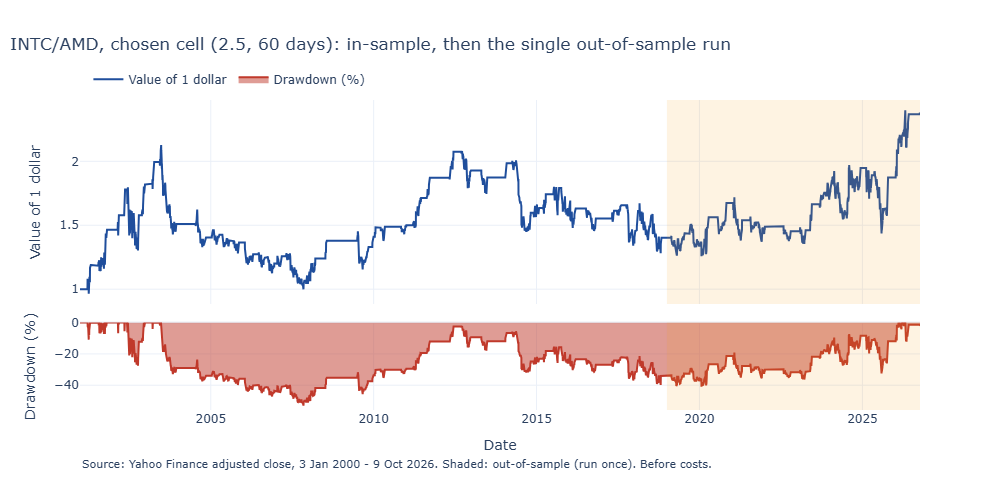

In [5]:
fig = equity_figure(
    pd.concat([chosen_is["ret"], oos["ret"]]),
    f"INTC/AMD, chosen cell ({entry}, {window} days): in-sample, then the single out-of-sample run",
    SOURCE_ALL + " Before costs.",
    shade_from=oos_start,
)
save_figure(fig, "08_equity_is_oos", figures_dir)
fig.show()

In-sample the chosen cell earns 3.5% a year with a Sharpe ratio of 0.19 (t-stat 0.82) and a worst
drawdown of −53%, a weak result. Out-of-sample the same cell earns 9.1% a year, Sharpe 0.42, t-stat 1.17,
27 trades. So my prediction was wrong. KO/PEP went from 0.35 in-sample to −0.53 out-of-sample; INTC/AMD
went from 0.19 to 0.42. Neither number reaches t = 2.

## 5. Does the hedge ratio stay put?

As in Phase 3, the OLS β of INTC on AMD re-estimated every day on the last 500 days (about two years).
This is only a description: nothing is chosen from it. The dashed line is the in-sample β used above.

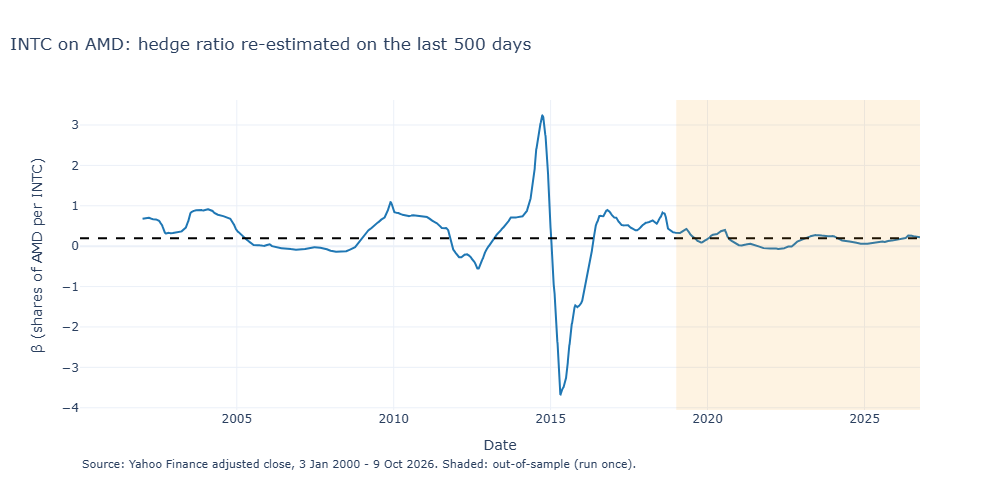

Date,2000-12-31,2001-12-31,2002-12-31,2003-12-31,2004-12-31,2005-12-31,2006-12-31,2007-12-31,2008-12-31,2009-12-31,...,2017-12-31,2018-12-31,2019-12-31,2020-12-31,2021-12-31,2022-12-31,2023-12-31,2024-12-31,2025-12-31,2026-12-31
β at year end,NaN,0.677,0.331,0.896,0.388,0.044,-0.085,-0.113,0.215,0.877,...,0.562,0.331,0.176,0.024,-0.059,0.16,0.255,0.057,0.156,0.221


In [6]:
roll_beta = rolling_hedge_ratio(all_prices, A, B, 500)
fig = go.Figure(
    go.Scatter(x=roll_beta.index, y=roll_beta, name="500-day rolling β", line={"color": "#1f77b4"})
)
fig.add_hline(y=fit.beta, line_dash="dash", line_color="black")
fig.add_vrect(x0=oos_start, x1=roll_beta.index[-1], fillcolor="#f39c12", opacity=0.12, line_width=0)
finish_figure(
    fig,
    "INTC on AMD: hedge ratio re-estimated on the last 500 days",
    "Date",
    "β (shares of AMD per INTC)",
    SOURCE_ALL,
)
save_figure(fig, "08_rolling_beta", figures_dir)
fig.show()
roll_beta.resample("YE").last().round(3).to_frame("β at year end").T

## 6. Conclusion

The rolling β shows why I would not trust the out-of-sample gain. At the end of each year it goes from
−1.36 (2015) to 0.90 (2003), and in the out-of-sample years it stays between −0.06 and 0.25, while the
backtest uses 0.195 for everything. A pair whose hedge ratio changes sign is not a stable relation.

On the two pairs the same procedure gives the same picture in-sample: a small effect that is not
significant. Out-of-sample one pair loses and the other gains, both with |t-stat| below 2. I read this as
evidence that the Phase 2 procedure does not find a repeatable edge, and that the KO/PEP loss and the
INTC/AMD gain are both mostly luck. This analysis was done after seeing the KO/PEP results, without
costs, without the Phase 1 data checks and with one pair only, so it is a weak test.

The 26 backtests of this notebook are in the trial log (25 in phase "ext-second-pair-grid", 1 in
"ext-second-pair-oos"). The cell below checks every number written in the text.

In [7]:
assert len(all_prices) == 6733 and gaps["calendar_days"].iloc[0] == 7 and len(big_moves) == 6
assert (
    big_moves.loc[pd.Timestamp("2016-04-22"), B] == 0.523
    and big_moves.loc[pd.Timestamp("2024-08-02"), A] == -0.261
)
assert round(fit.beta, 3) == 0.195 and chosen == (2.5, 60) and (zone > 0).sum().sum() == 1
assert (round(sharpe.min().min(), 2), round(sharpe.max().max(), 2)) == (-0.18, 0.19) and not (
    sharpe > 0
).all().all()
assert round(zone.loc[2.5, 60], 3) == 0.037 and trades.loc[2.5, 60] == 49
i, o = compare[("INTC/AMD", "in-sample")], compare[("INTC/AMD", "out-of-sample")]
assert (
    round(i["sharpe"], 2),
    round(i["t_stat"], 2),
    round(i["max_drawdown"], 2),
    round(i["ann_return"], 3),
) == (0.19, 0.82, -0.53, 0.035)
assert (round(o["sharpe"], 2), round(o["t_stat"], 2), round(o["ann_return"], 3), o["n_trades"]) == (
    0.42,
    1.17,
    0.091,
    27,
)
assert (
    round(compare[("KO/PEP", "in-sample")]["sharpe"], 2) == 0.35
    and round(compare[("KO/PEP", "out-of-sample")]["sharpe"], 2) == -0.53
)
yb = roll_beta.resample("YE").last().round(2)
assert (yb.min(), yb.idxmin().year, yb.max(), yb.idxmax().year) == (-1.36, 2015, 0.9, 2003)
assert (yb.loc["2019":].min(), yb.loc["2019":].max()) == (-0.06, 0.25)
assert (
    count_trials(trials_db, "ext-second-pair-grid") == 25
    and count_trials(trials_db, "ext-second-pair-oos") == 1
)
assert (figures_dir / "08_equity_is_oos.png").exists() and (
    figures_dir / "08_rolling_beta.png"
).exists()